# PillSnap: training and evaluating the pill-matching model

This notebook walks through the deep-learning part of PillSnap:

1. **Data**: synthetic pill photos rendered from the catalogue (runs anywhere). Swap in NLM C3PI (`scripts/download_c3pi.py`) or ePillID (`scripts/prepare_epillid.py`) for real training; the manifest format is the same.
2. **Cleanup**: every image goes through the same OpenCV cleanup the API uses (segment, crop, upright, CLAHE).
3. **Model**: `PillNet` = CNN backbone (ResNet-18 here, EfficientNet-B0 / ResNet-50 supported) with three heads: a 128-d **metric-learning embedding** (batch-hard triplet loss + normalised-softmax proxy loss), a **shape** classifier and a **colour** classifier.
4. **Evaluation**: retrieval against a reference gallery, exactly like the API: **top-1 / top-3 accuracy**, **confusion matrix**, shape/colour accuracy, calibration (temperature scaling, ECE) and the effect of the 70% confidence threshold.

Run from the `backend/` folder: `jupyter notebook notebooks/train_pill_model.ipynb`.

In [1]:
import os, sys, json, subprocess
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
DATA = Path("data/synth"); ART = Path("artifacts")
print("working dir:", ROOT)

working dir: /home/user/pillsnap/backend


## 1. Data
Render ~120 photos per pill (70/15/15 train/val/test) plus 6 reference images per pill for the matching gallery. Backgrounds, light colour, shadows, rotation, blur and JPEG quality vary.

In [2]:
if not (DATA / "index.json").exists():
    subprocess.run([sys.executable, "-m", "ml.synth", "--out", str(DATA), "--per-class", "120"], check=True)
rows = json.loads((DATA / "index.json").read_text())
from collections import Counter
print(len(rows), "images |", len({r["pill_id"] for r in rows}), "pills |", Counter(r["split"] for r in rows))

3528 images | 28 pills | Counter({'train': 2352, 'val': 504, 'test': 504, 'ref': 168})


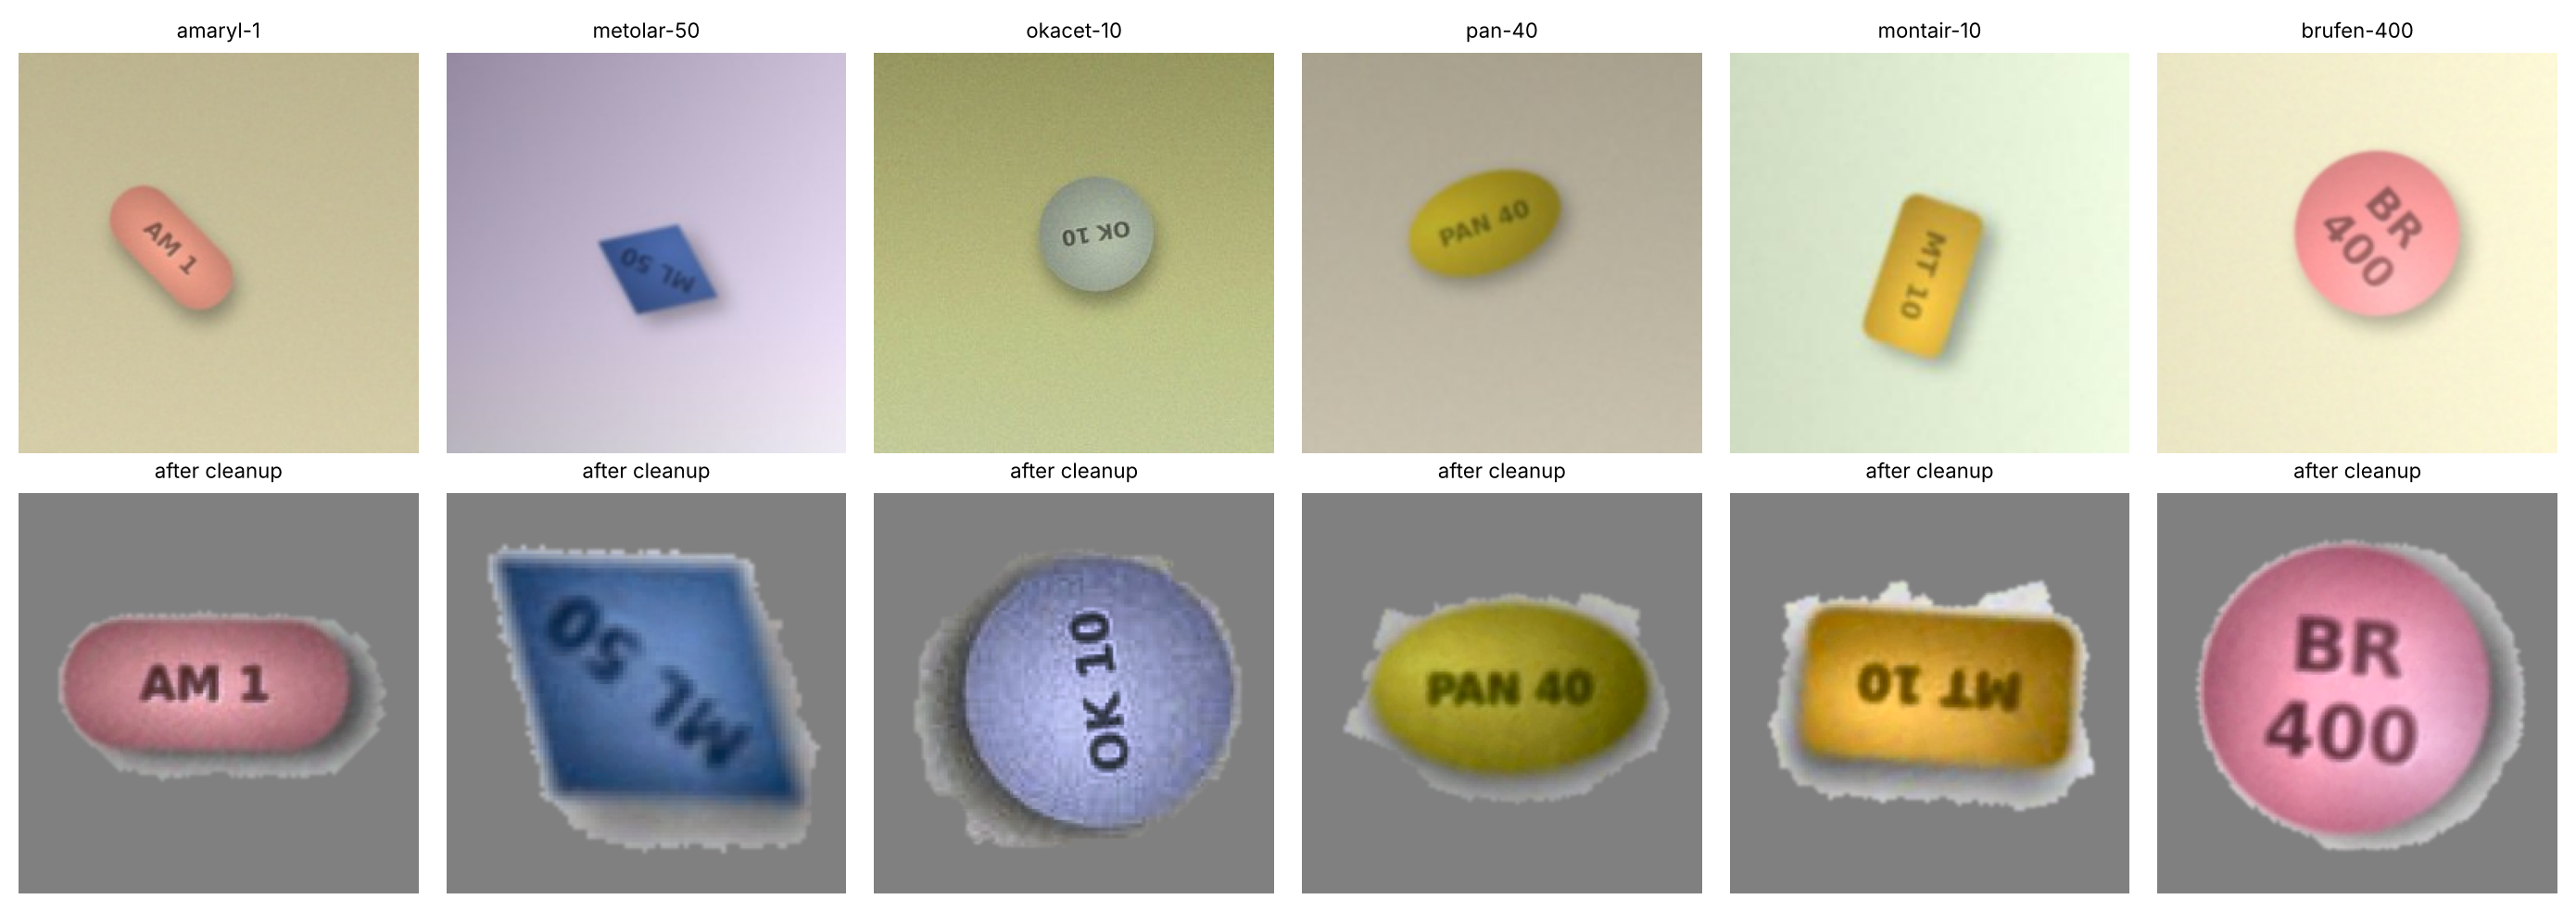

In [3]:
import matplotlib.pyplot as plt, cv2, random
from app.pipeline.preprocess import preprocess
random.seed(3)
pick = random.sample([r for r in rows if r["split"] == "train"], 6)
fig, ax = plt.subplots(2, 6, figsize=(14, 5))
for i, r in enumerate(pick):
    img = cv2.imread(str(DATA / r["path"]))
    ax[0, i].imshow(img[..., ::-1]); ax[0, i].set_title(r["pill_id"], fontsize=8)
    ax[1, i].imshow(preprocess(img).crop[..., ::-1]); ax[1, i].set_title("after cleanup", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.tight_layout()

## 2. Train PillNet
Loss = batch-hard triplet (P=16 pills x K=4 photos per batch) + normalised-softmax proxy loss (keeps the embedding space spread out) + 0.5 x (shape CE + colour CE). On CPU this takes about 12 minutes; with `--pretrained --backbone efficientnet_b0 --device cuda` on C3PI expect a few hours.

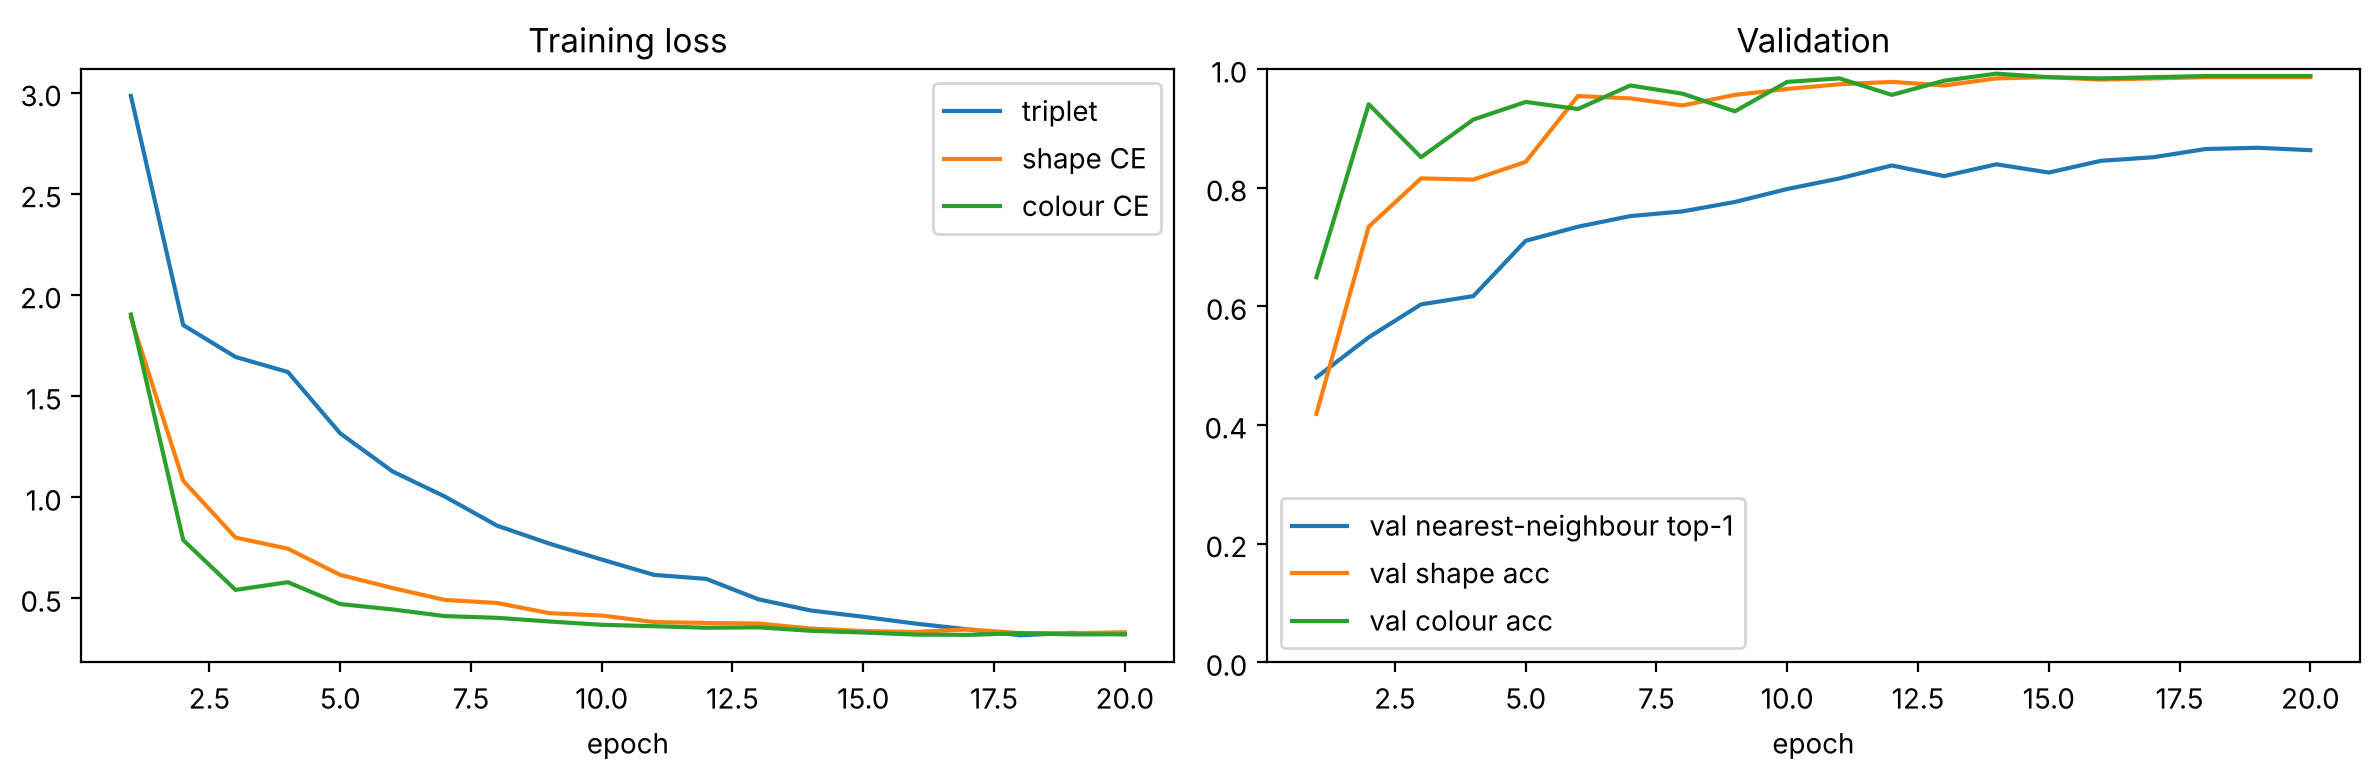

In [4]:
if not (ART / "pillnet.pt").exists():
    subprocess.run([sys.executable, "-m", "ml.train", "--data", str(DATA), "--epochs", "20"], check=True)
log = json.loads((ART / "train_log.json").read_text())["log"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ep = [l["epoch"] for l in log]
ax[0].plot(ep, [l["loss_triplet"] for l in log], label="triplet"); ax[0].plot(ep, [l["loss_shape"] for l in log], label="shape CE"); ax[0].plot(ep, [l["loss_color"] for l in log], label="colour CE")
ax[0].set_title("Training loss"); ax[0].legend(); ax[0].set_xlabel("epoch")
ax[1].plot(ep, [l["nn_top1"] for l in log], label="val nearest-neighbour top-1"); ax[1].plot(ep, [l["shape_acc"] for l in log], label="val shape acc"); ax[1].plot(ep, [l["color_acc"] for l in log], label="val colour acc")
ax[1].set_ylim(0, 1); ax[1].set_title("Validation"); ax[1].legend(); ax[1].set_xlabel("epoch")
plt.tight_layout()

## 3. Evaluate as the API does
Embed the reference gallery, match every test photo, fuse with the shape/colour heads, calibrate on val, report on test.

In [5]:
subprocess.run([sys.executable, "-m", "ml.evaluate", "--data", str(DATA)], check=True, capture_output=True)
m = json.loads((ART / "eval" / "metrics.json").read_text())
for k in ["n_test", "n_classes", "top1_accuracy", "top3_accuracy", "top5_accuracy", "shape_accuracy", "color_accuracy", "ece", "coverage_at_0.70", "accuracy_when_confident_at_0.70"]:
    v = m[k]; print(f"{k:34s} {v:.3f}" if isinstance(v, float) else f"{k:34s} {v}")

n_test                             504
n_classes                          28
top1_accuracy                      0.885
top3_accuracy                      0.984
top5_accuracy                      0.990
shape_accuracy                     0.984
color_accuracy                     0.990
ece                                0.035
coverage_at_0.70                   0.754
accuracy_when_confident_at_0.70    0.989


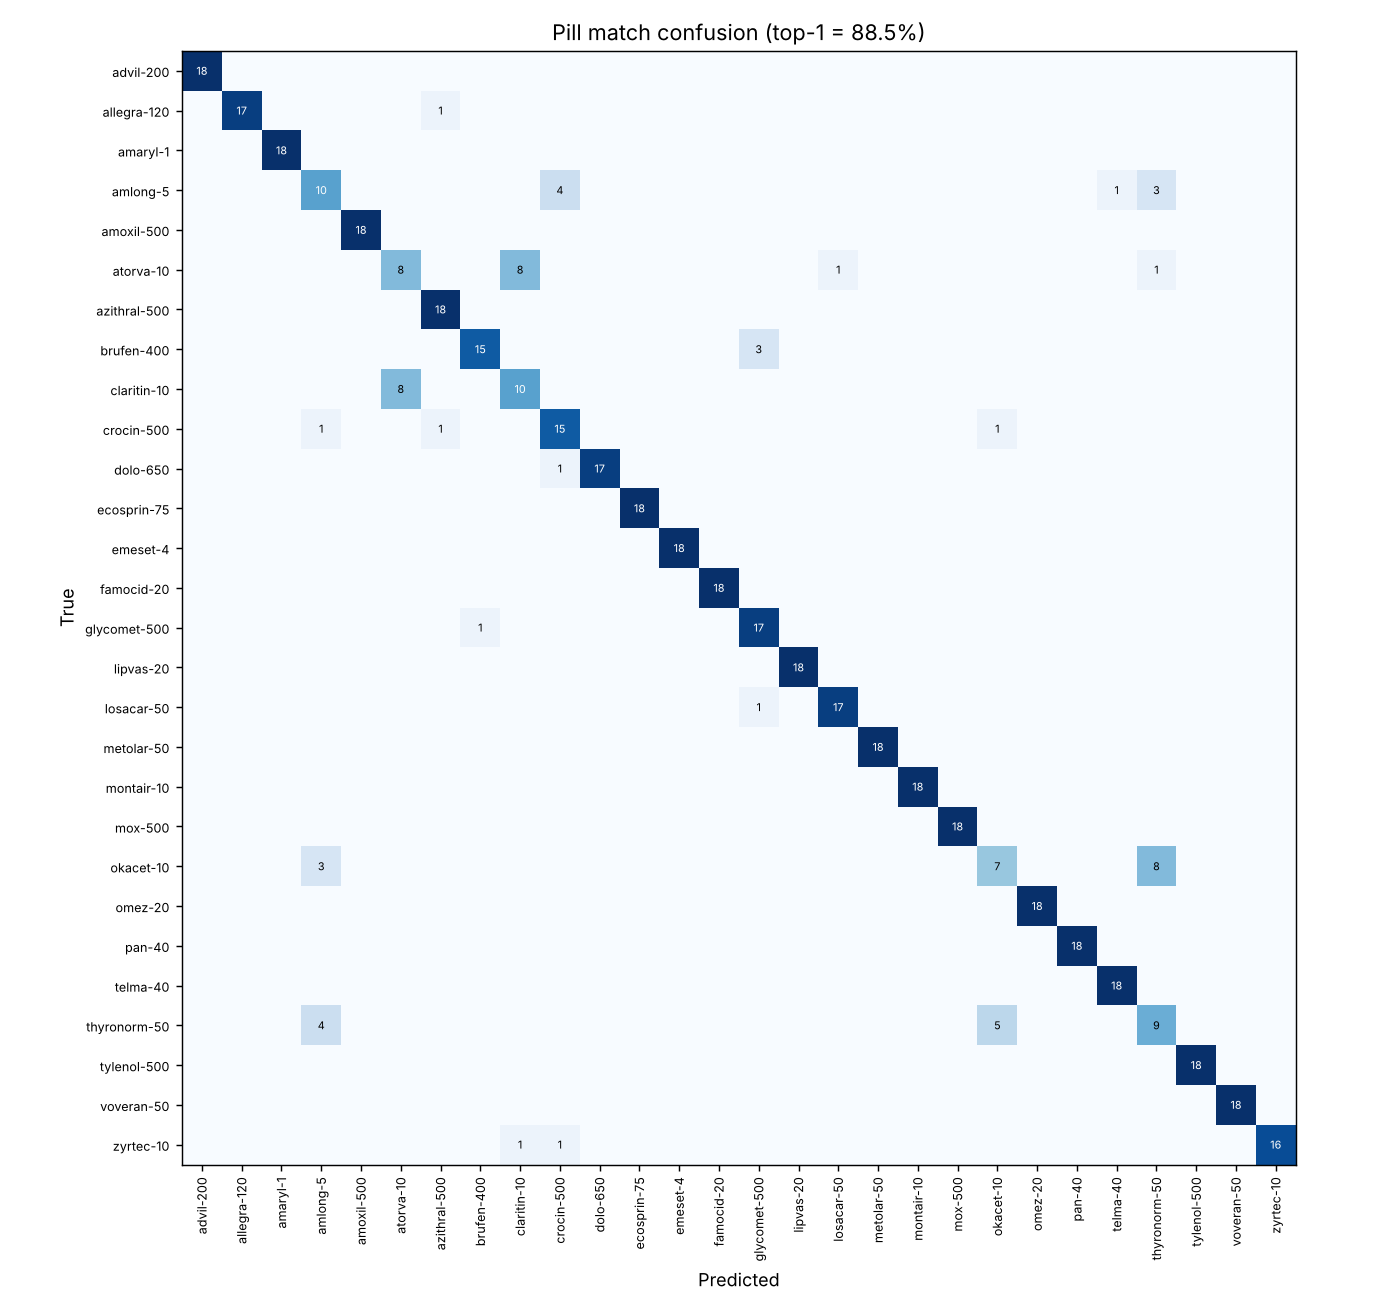

In [6]:
from IPython.display import Image, display
display(Image(filename=str(ART / "eval" / "confusion_matrix.png")))

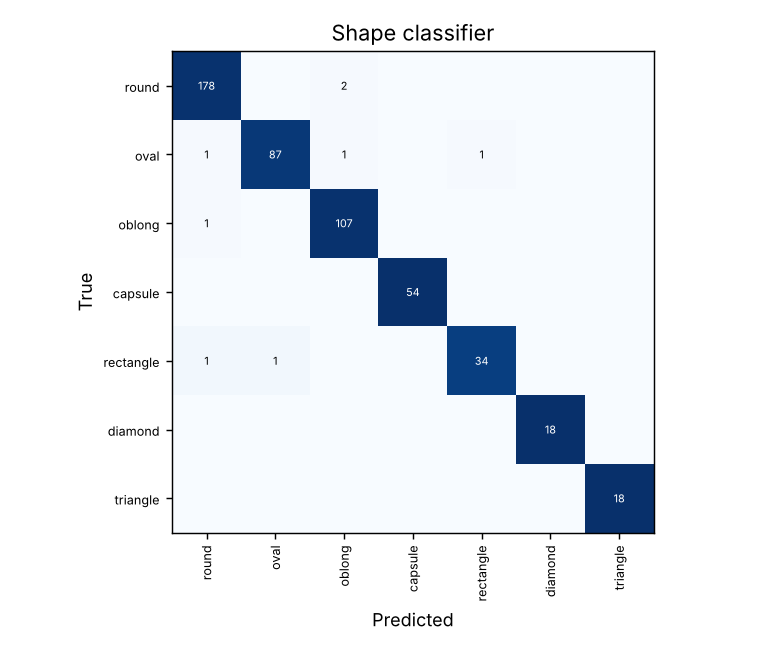

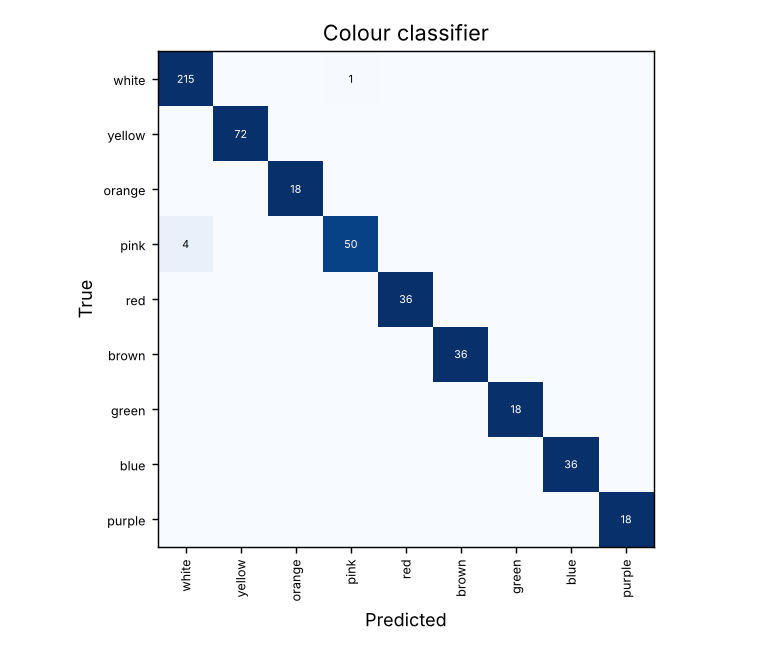

In [7]:
display(Image(filename=str(ART / "eval" / "shape_confusion.png"))); display(Image(filename=str(ART / "eval" / "color_confusion.png")))

## 4. What the embedding learned
A 2-D t-SNE of test embeddings. Pills with the same look (e.g. small white round tablets) sit close together. That is exactly why PillSnap refuses to give one answer without a matching imprint.

In [8]:
import numpy as np, torch
from sklearn.manifold import TSNE
from ml.models import load_model
from ml.datasets import PillDataset
from ml.evaluate import embed_split
model, ck = load_model(ART / "pillnet.pt")
ds = PillDataset(DATA, [r for r in rows if r["split"] == "test"], ck["classes"], ck["img_size"], train=False)
E, Y, *_ = embed_split(model, ds)
Z = TSNE(perplexity=25, init="pca", random_state=0).fit_transform(E)
plt.figure(figsize=(9, 7)); plt.scatter(Z[:, 0], Z[:, 1], c=Y, cmap="tab20", s=10)
for c in range(len(ck["classes"])):
    pts = Z[Y == c]
    if len(pts): plt.annotate(ck["classes"][c], pts.mean(0), fontsize=7)
plt.title("t-SNE of PillNet embeddings (test set)"); plt.axis("off")

(np.float64(-30.879068088531493),
 np.float64(25.829395008087157),
 np.float64(-33.25395650863648),
 np.float64(29.54161329269409))

## 5. Full pipeline on one photo (with OCR)
The evaluation above excludes imprint OCR. Here is the full pipeline, including EasyOCR, on test images.

In [9]:
from fastapi.testclient import TestClient
os.environ.setdefault("PILLSNAP_LLM", "off")
from app.main import app
ok = 0; N = 12
test_rows = [r for r in rows if r["split"] == "test"]; random.seed(0); random.shuffle(test_rows)
with TestClient(app) as client:
    for r in test_rows[:N]:
        res = client.post("/api/identify", files={"image": ("p.jpg", open(DATA / r["path"], "rb").read(), "image/jpeg")}).json()
        top = res["matches"][0]
        ok += top["pill"]["pill_id"] == r["pill_id"]
        print(f'{r["pill_id"]:14s} -> {top["pill"]["pill_id"]:14s} {top["confidence"]:.2f} {res["status"]:19s} imprint={res["detected"]["imprint"]["text"]!r}')
print(f"full-pipeline top-1 on {N} photos: {ok}/{N}")

2026-11-25 17:09:30,348 INFO app.pipeline.pipeline: PillNet loaded (resnet18, 168 gallery images)


/home/user/.venv-pillsnap/lib/python3.13/site-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(


/home/user/.venv-pillsnap/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


2026-11-25 17:09:34,302 INFO httpx2: HTTP Request: POST http://testserver/api/identify "HTTP/1.1 200 OK"


montair-10     -> montair-10     0.99 confident           imprint='MT 10'


2026-11-25 17:09:35,332 INFO httpx2: HTTP Request: POST http://testserver/api/identify "HTTP/1.1 200 OK"


... (17 outputs left out)

2026-11-25 17:09:46,155 INFO httpx2: HTTP Request: POST http://testserver/api/identify "HTTP/1.1 200 OK"


amlong-5       -> amlong-5       0.99 confident           imprint='AML 5'


2026-11-25 17:09:48,396 INFO httpx2: HTTP Request: POST http://testserver/api/identify "HTTP/1.1 200 OK"


famocid-20     -> famocid-20     0.69 needs_confirmation  imprint='0 02'
full-pipeline top-1 on 12 photos: 12/12


## Notes and next steps
- These numbers are on **synthetic** photos. Real-world accuracy must be measured on ePillID consumer photos (the standard benchmark) after training on C3PI reference + consumer images.
- For real training use `--pretrained` (ImageNet weights) and a larger image size (224).
- Add Indian medicines by photographing reference pills (6+ photos each on a plain background) and adding records to `app/data/pills.json`, then rebuild the index with `python -m ml.build_index`: no retraining needed thanks to metric learning.